### Checking Data and It's Quality

In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

df = pd.read_csv('export.csv') 

df.head()

,VIN (1-10),County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Legislative District,DOL Vehicle ID,Vehicle Location,Electric Utility,2020 GEOID
0,1N4AZ1CP3K,King,Shoreline,WA,98155.0,2019,NISSAN,LEAF,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,150.0,32.0,168526641,POINT (-122.30304 47.75494),CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),5.303302e+10
1,WBY8P4C51K,King,Kirkland,WA,98033.0,2019,BMW,I3,Plug-in Hybrid Electric Vehicle (PHEV),Clean Alternative Fuel Vehicle Eligible,126.0,48.0,9418181,POINT (-122.2066 47.67887),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),5.303302e+10
2,3FA6P0SU8G,Snohomish,Lynnwood,WA,98036.0,2016,FORD,FUSION,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,19.0,1.0,172853495,POINT (-122.29245 47.82557),PUGET SOUND ENERGY INC,5.306105e+10
3,5YJ3E1EB3N,Yakima,Wapato,WA,98951.0,2022,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.0,15.0,204768175,POINT (-120.42083 46.44779),PACIFICORP,5.307794e+10
4,WBY1Z2C53F,King,Renton,WA,98055.0,2015,BMW,I3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,81.0,11.0,269262920,POINT (-122.19488 47.44034),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),5.303303e+10


In [3]:
df.info() 


df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299705 entries, 0 to 299704
Data columns (total 16 columns):
 #   Column                                             Non-Null Count   Dtype  
---  ------                                             --------------   -----  
 0   VIN (1-10)                                         299705 non-null  object 
 1   County                                             299694 non-null  object 
 2   City                                               299694 non-null  object 
 3   State                                              299705 non-null  object 
 4   Postal Code                                        299694 non-null  float64
 5   Model Year                                         299705 non-null  int64  
 6   Make                                               299705 non-null  object 
 7   Model                                              299705 non-null  object 
 8   Electric Vehicle Type                              299705 non-null  object

,Postal Code,Model Year,Electric Range,Legislative District,DOL Vehicle ID,2020 GEOID
count,299694.000000,299705.000000,299679.000000,298915.000000,2.997050e+05,2.996940e+05
mean,98176.001962,2022.344666,36.663313,28.754589,2.509924e+08,5.296742e+10
std,2652.053836,3.093007,76.034423,14.892388,6.238702e+07,1.687605e+09
min,1030.000000,1999.000000,0.000000,1.000000,4.469000e+03,1.001020e+09
25%,98052.000000,2021.000000,0.000000,17.000000,2.283017e+08,5.303301e+10
50%,98134.000000,2023.000000,0.000000,32.000000,2.679271e+08,5.303303e+10
75%,98391.000000,2024.000000,32.000000,42.000000,2.845359e+08,5.305394e+10
max,99801.000000,2027.000000,337.000000,49.000000,4.791150e+08,6.601095e+10


In [4]:
print(df.duplicated().sum())

df.isnull().mean()

0


VIN (1-10)                                           0.000000
County                                               0.000037
City                                                 0.000037
State                                                0.000000
Postal Code                                          0.000037
Model Year                                           0.000000
Make                                                 0.000000
Model                                                0.000000
Electric Vehicle Type                                0.000000
Clean Alternative Fuel Vehicle (CAFV) Eligibility    0.000000
Electric Range                                       0.000087
Legislative District                                 0.002636
DOL Vehicle ID                                       0.000000
Vehicle Location                                     0.000067
Electric Utility                                     0.000037
2020 GEOID                                           0.000037
dtype: f

### More About the Data

In [5]:
df["Make"].value_counts(ascending=False)

Make
TESLA                     122981
CHEVROLET                  20236
FORD                       16118
NISSAN                     16053
KIA                        14776
TOYOTA                     13998
BMW                        12356
HYUNDAI                    12351
RIVIAN                      9817
VOLVO                       8187
VOLKSWAGEN                  7919
JEEP                        6177
AUDI                        6138
SUBARU                      3640
CHRYSLER                    3634
MERCEDES-BENZ               3491
HONDA                       3266
CADILLAC                    2883
LEXUS                       2188
PORSCHE                     2152
POLESTAR                    1696
MAZDA                       1693
MITSUBISHI                  1303
MINI                        1261
LUCID                        916
FIAT                         857
GMC                          623
GENESIS                      555
DODGE                        498
LINCOLN                      494
ACURA

In [6]:
df.groupby('Electric Vehicle Type').groups.keys()

dict_keys(['Battery Electric Vehicle (BEV)', 'Plug-in Hybrid Electric Vehicle (PHEV)'])

In [7]:
df.groupby('State').groups.keys()

dict_keys(['AE', 'AK', 'AL', 'AR', 'AZ', 'BC', 'CA', 'CO', 'CT', 'DC', 'DE', 'FL', 'GA', 'GU', 'HI', 'IA', 'ID', 'IL', 'IN', 'KS', 'KY', 'LA', 'MA', 'MD', 'ME', 'MI', 'MN', 'MO', 'MS', 'MT', 'NC', 'NE', 'NH', 'NJ', 'NM', 'NV', 'NY', 'OH', 'OR', 'PA', 'RI', 'SC', 'SD', 'TN', 'TX', 'UT', 'VA', 'WA', 'WI', 'WY'])

In [8]:
df.groupby('State').size().sort_values(ascending=False)

State
WA    298916
CA       180
VA       105
MD        46
TX        46
FL        44
OR        28
NV        27
CO        25
AZ        25
NC        20
IL        19
GA        17
IN        14
NY        14
ID        12
MO        11
NJ        11
DC        10
TN        10
AL         9
PA         8
MI         8
MA         8
NE         7
BC         6
CT         6
SC         5
NM         5
RI         5
KS         5
KY         5
OH         5
AE         4
WI         4
NH         4
LA         4
MN         4
HI         4
UT         3
AR         2
IA         2
SD         2
WY         2
GU         2
ME         2
DE         1
AK         1
MS         1
MT         1
dtype: int64

In [9]:
df.groupby('Model')['Model Year'].min().sort_values()

Model
RANGER        1999
RAV4          2002
ROADSTER      2008
WHEEGO        2010
CITY          2011
              ... 
POLESTAR 4    2026
ROGUE         2026
TEMERARIO     2026
BOLT          2027
R2            2027
Name: Model Year, Length: 202, dtype: int64

In [10]:
result = df.groupby('Model').agg(
    Make=('Make', 'first'),
    Launch_Year=('Model Year', 'min')
).reset_index()


result.sort_values('Launch_Year')

,Model,Make,Launch_Year
146,RANGER,FORD,1999
147,RAV4,TOYOTA,2002
152,ROADSTER,TESLA,2008
192,WHEEGO,WHEEGO ELECTRIC CARS,2010
39,CITY,TH!NK,2011
...,...,...,...
131,POLESTAR 4,POLESTAR,2026
153,ROGUE,NISSAN,2026
177,TEMERARIO,LAMBORGHINI,2026
26,BOLT,CHEVROLET,2027


### Want to see Tesla(Model)

In [11]:
tesla = df[df["Make"].str.strip().str.upper() == "TESLA"]

# Count of each model
model_counts = tesla["Model"].value_counts()
print(model_counts)

# As a clean DataFrame (good for saving or plotting)
model_counts = (
    tesla["Model"]
    .value_counts()
    .reset_index()
)
model_counts.columns = ["Model", "Count"]
print(model_counts)

# With percentage share
model_share = tesla["Model"].value_counts(normalize=True).mul(100).round(2)
print(model_share)


Model
MODEL Y       66545
MODEL 3       39391
MODEL S        7873
MODEL X        7177
CYBERTRUCK     1954
ROADSTER         41
Name: count, dtype: int64
        Model  Count
0     MODEL Y  66545
1     MODEL 3  39391
2     MODEL S   7873
3     MODEL X   7177
4  CYBERTRUCK   1954
5    ROADSTER     41
Model
MODEL Y       54.11
MODEL 3       32.03
MODEL S        6.40
MODEL X        5.84
CYBERTRUCK     1.59
ROADSTER       0.03
Name: proportion, dtype: float64


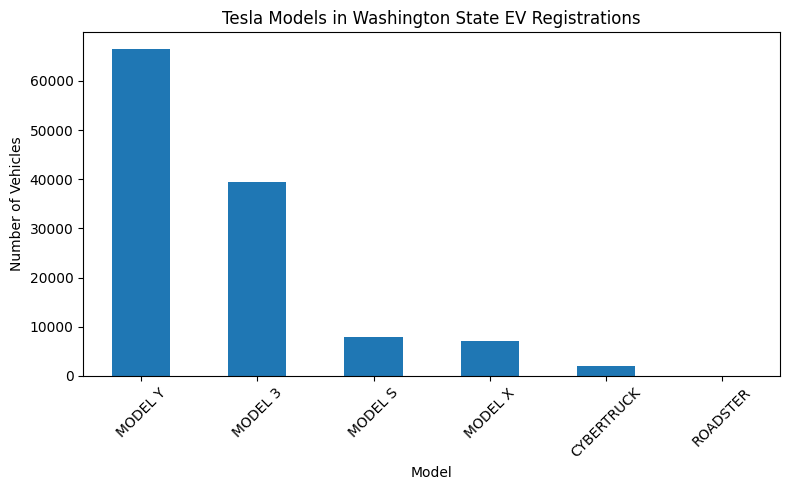

In [12]:
model_counts.plot(kind="bar", x="Model", y="Count", legend=False, figsize=(8, 5))
plt.title("Tesla Models in Washington State EV Registrations")
plt.ylabel("Number of Vehicles")
plt.xticks(rotation=45)
plt.tight_layout()

<Axes: title={'center': 'Top 15 make + model combinations'}, xlabel='Number of registered vehicles'>

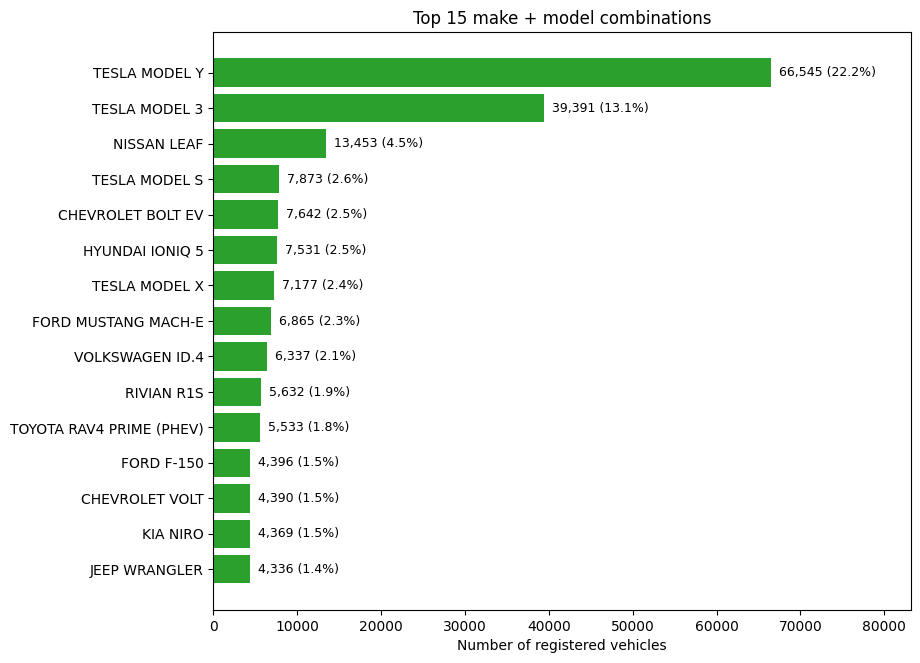

In [49]:
def barh_top(series, n, title, color="#1f77b4", figsize=None):
    """Horizontal bar chart of the top-n categories, annotated with count and share."""
    counts = series.value_counts().head(n).sort_values()
    fig, ax = plt.subplots(figsize=figsize or (9, 0.38 * n + 1.8))
    ax.barh(counts.index.astype(str), counts.values, color=color)
    for i, v in enumerate(counts.values):
        ax.text(v, i, f"  {v:,} ({v / len(series):.1%})", va="center", fontsize=9)
    ax.set_xlim(0, counts.max() * 1.25)
    ax.set_title(title)
    ax.set_xlabel("Number of registered vehicles")
    ax.grid(axis="y", visible=False)
    return ax

make_model = df["Make"] + " " + df["Model"]
barh_top(make_model, 15, "Top 15 make + model combinations", color="#2ca02c")

### Just want to see the Electric vehicle type

In [13]:
df['Electric Vehicle Type'].value_counts()

"""  
1. Battery Electric Vehicle (BEV) has more type of vehicle then Plug-in Hybrid Electric Vehicle (PHEV).
2. If we want to gain some profit, then we need to do more focus on 'BEV' type vehicles.
3. Here we see clear 80.7% market is captured by 'BEV' type charging vehicles.

"""

"  \n1. Battery Electric Vehicle (BEV) has more type of vehicle then Plug-in Hybrid Electric Vehicle (PHEV).\n2. If we want to gain some profit, then we need to do more focus on 'BEV' type vehicles.\n3. Here we see clear 80.7% market is captured by 'BEV' type charging vehicles.\n\n"

<Axes: ylabel='count'>

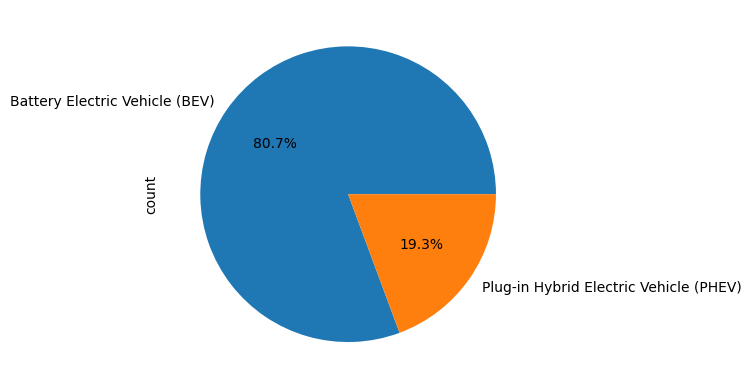

In [14]:
df['Electric Vehicle Type'].value_counts().plot(kind='pie', autopct='%1.1f%%')

### Electric Utility

In [15]:
df['Electric Utility'].value_counts()

""" 
1. PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA) has highest utility.
2. This utility company has 34.7% market domainace . 

"""

' \n1. PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA) has highest utility.\n2. This utility company has 34.7% market domainace . \n\n'

In [16]:
# df['Electric Utility'].value_counts().plot(kind='pie', autopct='%1.1f%%')
df['Electric Utility'].value_counts()

Electric Utility
PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA)                                               103988
PUGET SOUND ENERGY INC                                                                       63791
CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA)                                                 48888
BONNEVILLE POWER ADMINISTRATION||PUD NO 1 OF CLARK COUNTY - (WA)                             18318
BONNEVILLE POWER ADMINISTRATION||CITY OF TACOMA - (WA)||PENINSULA LIGHT COMPANY              13964
                                                                                             ...  
CITY OF SEATTLE - (WA)                                                                           1
BONNEVILLE POWER ADMINISTRATION||PUD NO 1 OF ASOTIN COUNTY                                       1
BONNEVILLE POWER ADMINISTRATION||PENINSULA LIGHT COMPANY                                         1
BONNEVILLE POWER ADMINISTRATION||PUD NO 1 OF CLALLAM COUNTY|PUD NO 1 OF JEFFERSON COUNTY    

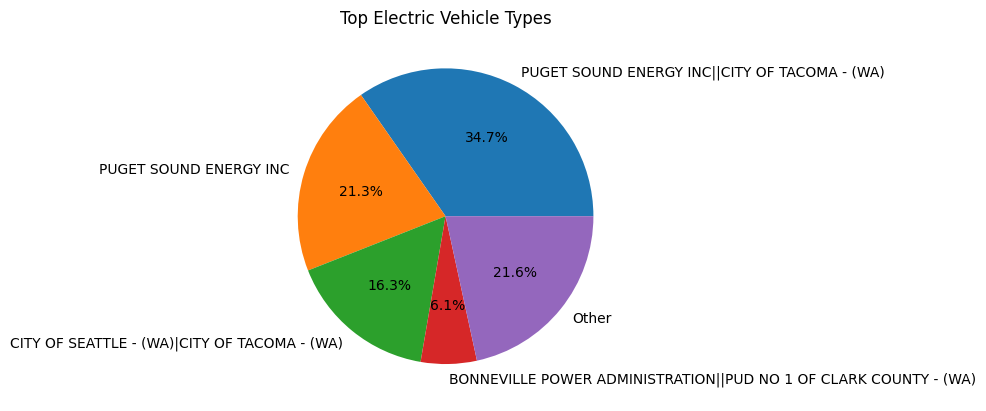

In [17]:
counts = df['Electric Utility'].value_counts()

# 2. Keep the top 4 categories (you can change this number)
top_counts = counts.nlargest(4)

# 3. Sum the remaining categories into an 'Other' slice
other_counts = pd.Series({'Other': counts.iloc[4:].sum()})

# 4. Combine them and plot
final_counts = pd.concat([top_counts, other_counts])
final_counts.plot(kind='pie', autopct='%1.1f%%', ylabel='')

plt.title('Top Electric Vehicle Types')
plt.show()

### Customer of  PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA)  in TACOMA

In [27]:

# df[df['City'] == 'Tacoma']
mask = df['City '] == 'Tacoma'
mask[mask].value_counts()

df.loc[mask, 'Electric Utility'].unique()


array(['BONNEVILLE POWER ADMINISTRATION||CITY OF TACOMA - (WA)||PENINSULA LIGHT COMPANY',
       'BONNEVILLE POWER ADMINISTRATION||CITY OF TACOMA - (WA)||ELMHURST MUTUAL POWER & LIGHT CO|PENINSULA LIGHT COMPANY',
       'BONNEVILLE POWER ADMINISTRATION||CITY OF TACOMA - (WA)||PARKLAND LIGHT & WATER COMPANY|PENINSULA LIGHT COMPANY',
       'BONNEVILLE POWER ADMINISTRATION||CITY OF TACOMA - (WA)||LAKEVIEW LIGHT & POWER|PENINSULA LIGHT COMPANY',
       'PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA)',
       'BONNEVILLE POWER ADMINISTRATION||CITY OF MILTON - (WA)|CITY OF TACOMA - (WA)',
       'BONNEVILLE POWER ADMINISTRATION||TOWN OF RUSTON - (WA)|CITY OF TACOMA - (WA)||PENINSULA LIGHT COMPANY',
       'BONNEVILLE POWER ADMINISTRATION||PENINSULA LIGHT COMPANY'],
      dtype=object)

In [28]:
utility = "PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA)"

data = df[df["Electric Utility"] == utility]

city_counts = data["City "].value_counts()
print(city_counts)

city_counts = data["City "].value_counts().reset_index()
city_counts.columns = ["City ", "Count"]
city_counts["Percent"] = (city_counts["Count"] / city_counts["Count"].sum() * 100).round(2)

print(city_counts)

City 
Bellevue       14383
Redmond        10135
Kirkland        8487
Sammamish       8129
Renton          7891
               ...  
Mcchord Afb        2
Vader              1
Mckenna            1
Parkland           1
Belfair            1
Name: count, Length: 77, dtype: int64
          City   Count  Percent
0      Bellevue  14383    13.83
1       Redmond  10135     9.75
2      Kirkland   8487     8.16
3     Sammamish   8129     7.82
4        Renton   7891     7.59
..          ...    ...      ...
72  Mcchord Afb      2     0.00
73        Vader      1     0.00
74      Mckenna      1     0.00
75     Parkland      1     0.00
76      Belfair      1     0.00

[77 rows x 3 columns]


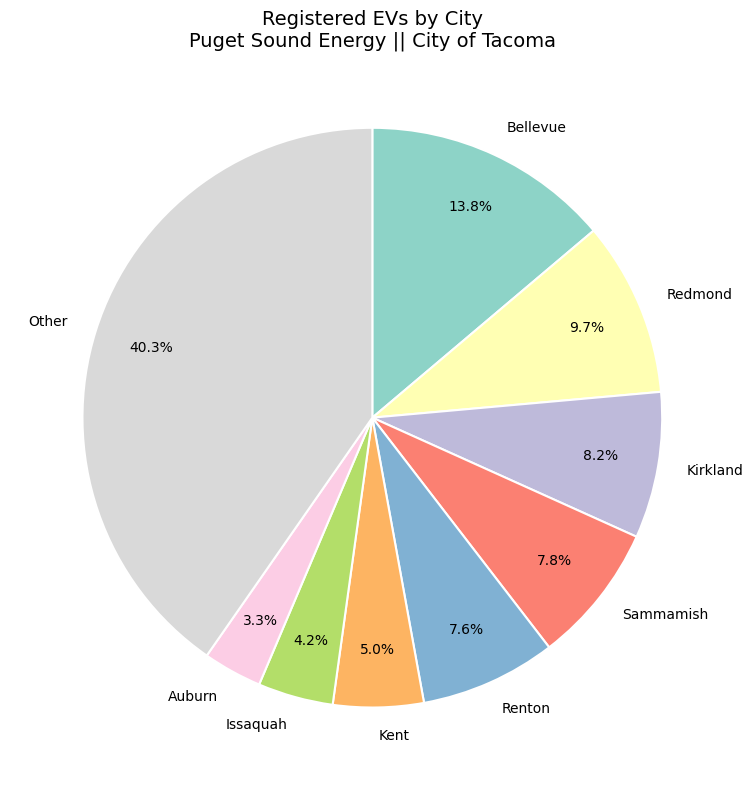

In [30]:
utility = "PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA)"
data = df[df["Electric Utility"] == utility]

city_counts = data["City "].value_counts()

# Keep top 8 cities, group the rest as "Other"
top_n = 8
top = city_counts.head(top_n)
other = city_counts.iloc[top_n:].sum()
plot_data = pd.concat([top, pd.Series({"Other": other})])

# Plot
fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(
    plot_data,
    labels=plot_data.index,
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    pctdistance=0.8,
    colors=plt.cm.Set3.colors,
    wedgeprops={"edgecolor": "white", "linewidth": 1.5},
)

ax.set_title("Registered EVs by City\nPuget Sound Energy || City of Tacoma", fontsize=14)
plt.tight_layout()

### Model year – the adoption curve

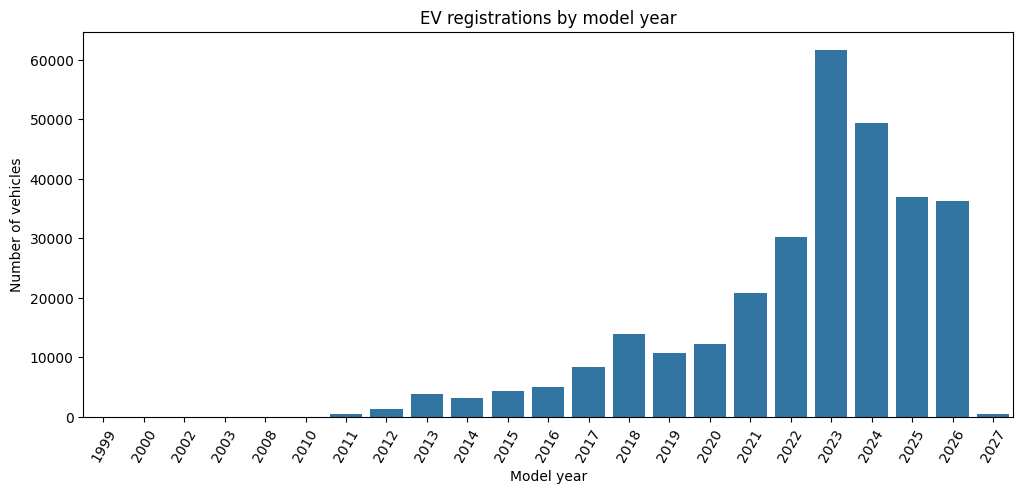

In [33]:
year_counts = df["Model Year"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(x=year_counts.index, y=year_counts.values, color="#1f77b4", ax=ax)
ax.set_title("EV registrations by model year")
ax.set_xlabel("Model year")
ax.set_ylabel("Number of vehicles")
ax.tick_params(axis="x", rotation=60)
# save_fig("04_model_year_distribution")

**Insight:** Registrations climbed through 2018, stayed roughly flat during 2018–2020, then **took off from model year 2021** and peaked at model year 2023 (~62k vehicles). The tiny 2027 bar reflects early releases of next-year models.

### Electric Range 

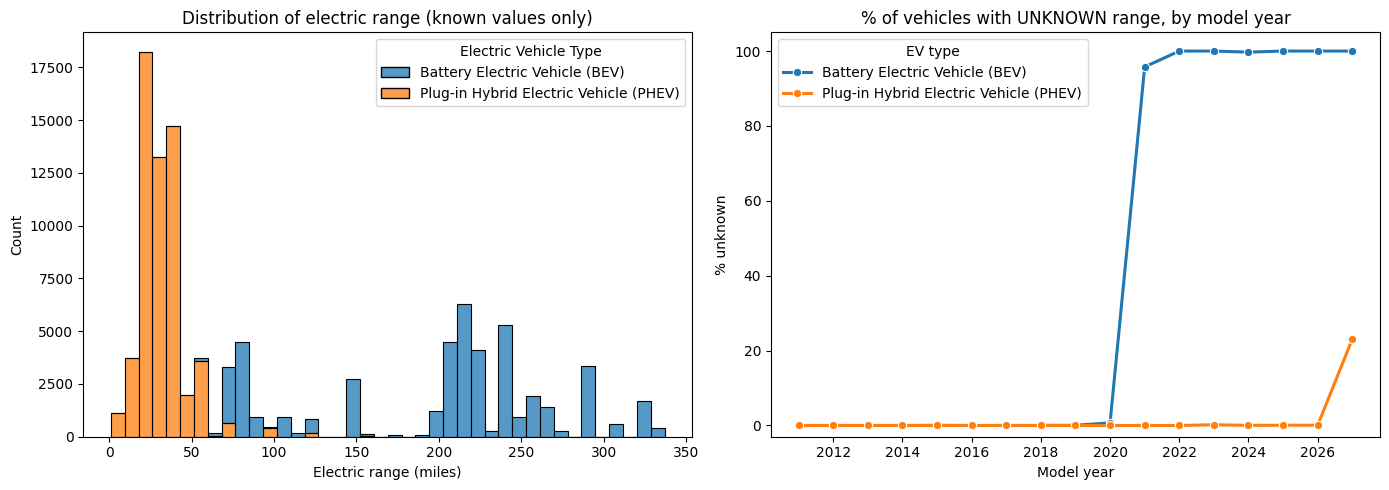

count    103444.0
mean        106.2
std          96.8
min           1.0
25%          30.0
50%          47.0
75%         215.0
max         337.0


In [ ]:

PALETTE = ["#1f77b4", "#ff7f0e"]          # one colour per EV type (BEV, PHEV)

def save_fig(name):
    plt.tight_layout()
    # plt.savefig(f"{name}.png", dpi=150, bbox_inches="tight")  # uncomment to save
    plt.show()

# --- use the actual column names from the CSV ---
EV_TYPE = "Electric Vehicle Type"
YEAR    = "Model Year"
RANGE   = "Electric Range"

# In this WA DOL dataset a range of 0 means "not researched/unknown",
# so treat 0 as missing as well as real NaNs
df["electric_range_known"] = df[RANGE].replace(0, np.nan)
known = df.dropna(subset=["electric_range_known"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: distribution of known range
sns.histplot(data=known, x="electric_range_known", hue=EV_TYPE, bins=40,
             multiple="stack", palette=PALETTE, ax=axes[0])
axes[0].set_title("Distribution of electric range (known values only)")
axes[0].set_xlabel("Electric range (miles)")

# Right: share of vehicles with unknown range, by model year AND EV type
unknown = (df.groupby([YEAR, EV_TYPE])["electric_range_known"]
             .apply(lambda s: s.isna().mean() * 100)
             .rename("pct_unknown").reset_index())
unknown = unknown[unknown[YEAR] >= 2011]

sns.lineplot(data=unknown, x=YEAR, y="pct_unknown", hue=EV_TYPE, palette=PALETTE,
             marker="o", linewidth=2.2, ax=axes[1])
axes[1].set_title("% of vehicles with UNKNOWN range, by model year")
axes[1].set_xlabel("Model year")
axes[1].set_ylabel("% unknown")
axes[1].set_ylim(-3, 105)
axes[1].legend(title="EV type")
save_fig("05_electric_range")

print(known["electric_range_known"].describe().round(1).to_string())

 **Insight:** Known ranges form two clusters: **~20–40 miles (PHEVs)** and **~70–340 miles (BEVs)**. The right-hand chart reveals the real data problem: the range is missing for **virtually every BEV from model year 2021 onward**, while PHEVs are always complete. So any range-based conclusion about BEVs **describes model years ≤ 2020** and must not be read as representative of today's fleet.

### CAFV eligibility

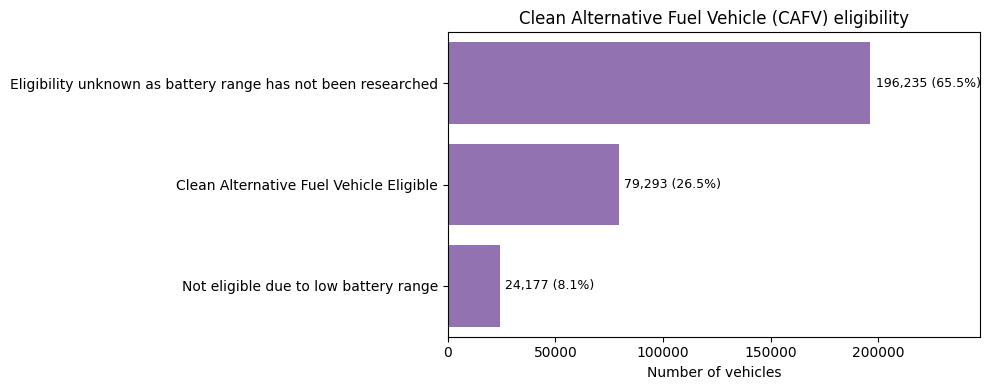

In [43]:
fig, ax = plt.subplots(figsize=(10, 4))
order = df["Clean Alternative Fuel Vehicle (CAFV) Eligibility"].value_counts().index
sns.countplot(data=df, y="Clean Alternative Fuel Vehicle (CAFV) Eligibility", order=order, color="#9467bd", ax=ax)
for c in ax.containers:
    ax.bar_label(c, labels=[f"{int(v):,} ({v / len(df):.1%})" for v in c.datavalues], padding=4, fontsize=9)
ax.set_xlim(0, ax.get_xlim()[1] * 1.2)
ax.set_title("Clean Alternative Fuel Vehicle (CAFV) eligibility")
ax.set_xlabel("Number of vehicles"); ax.set_ylabel("")
save_fig("06_cafv_eligibility")


## Bivariate Analysis

Text(0.5, 1.0, 'BEV vs PHEV share by model year (%)')

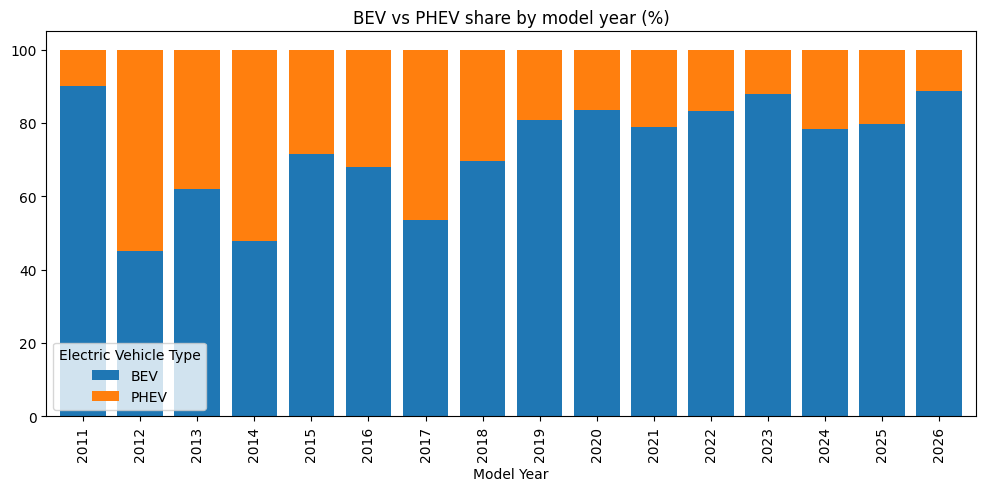

In [54]:
PALETTE = {"BEV": "#1f77b4", "PHEV": "#ff7f0e"}

df["Electric Vehicle Type"] = df["Electric Vehicle Type"].map({
    "Battery Electric Vehicle (BEV)": "BEV",
    "Plug-in Hybrid Electric Vehicle (PHEV)": "PHEV",
})

share = (pd.crosstab(df["Model Year"], df["Electric Vehicle Type"], normalize="index") * 100).loc[2011:2026]

ax = share[["BEV", "PHEV"]].plot.bar(stacked=True, figsize=(12, 5), color=[PALETTE["BEV"], PALETTE["PHEV"]], width=0.8)
ax.set_title("BEV vs PHEV share by model year (%)")

**Insight:** In model years 2011–2018 PHEVs were a big slice of the market (BEVs were only ~45–70% in most of those years). Since 2019 the **BEV share has settled at roughly 80–90%** and has plateaued there rather than continuing to climb.

### BEV share per make (top 10 makes)

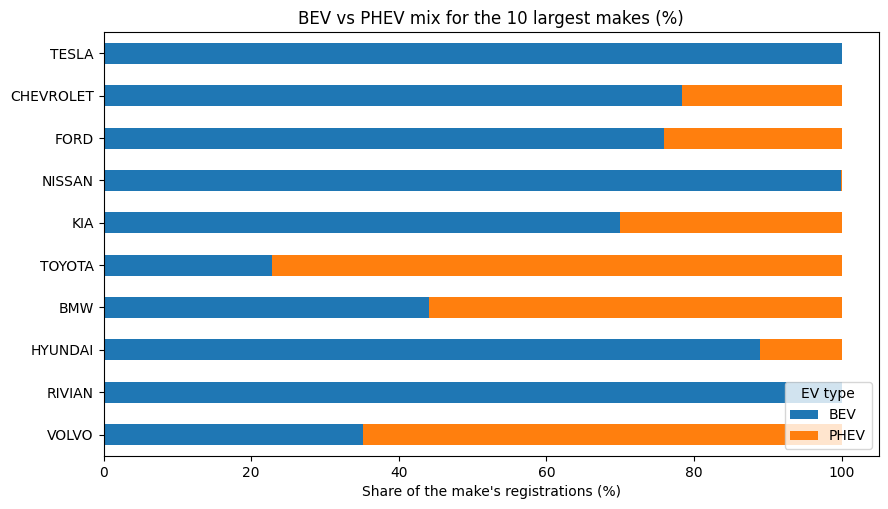

In [57]:
top10_makes = df["Make"].value_counts().head(10).index.tolist()
make_type = (pd.crosstab(df.loc[df["Make"].isin(top10_makes), "Make"], df["Electric Vehicle Type"], normalize="index") * 100).loc[top10_makes]

ax = make_type[["BEV", "PHEV"]].iloc[::-1].plot.barh(stacked=True, figsize=(10, 5.5), color=[PALETTE["BEV"], PALETTE["PHEV"]])
ax.set_title("BEV vs PHEV mix for the 10 largest makes (%)")
ax.set_xlabel("Share of the make's registrations (%)"); ax.set_ylabel("")
ax.legend(title="EV type", loc="lower right")

**Insight:** **Tesla, Nissan and Rivian are 100% BEV**. Chevrolet, Ford, Kia and Hyundai are mostly BEV (~70–90%), but **Toyota (~23% BEV), Volvo (~35%) and BMW (~44%) sell mainly plug-in hybrids**. This mix difference matters when comparing range across makes.

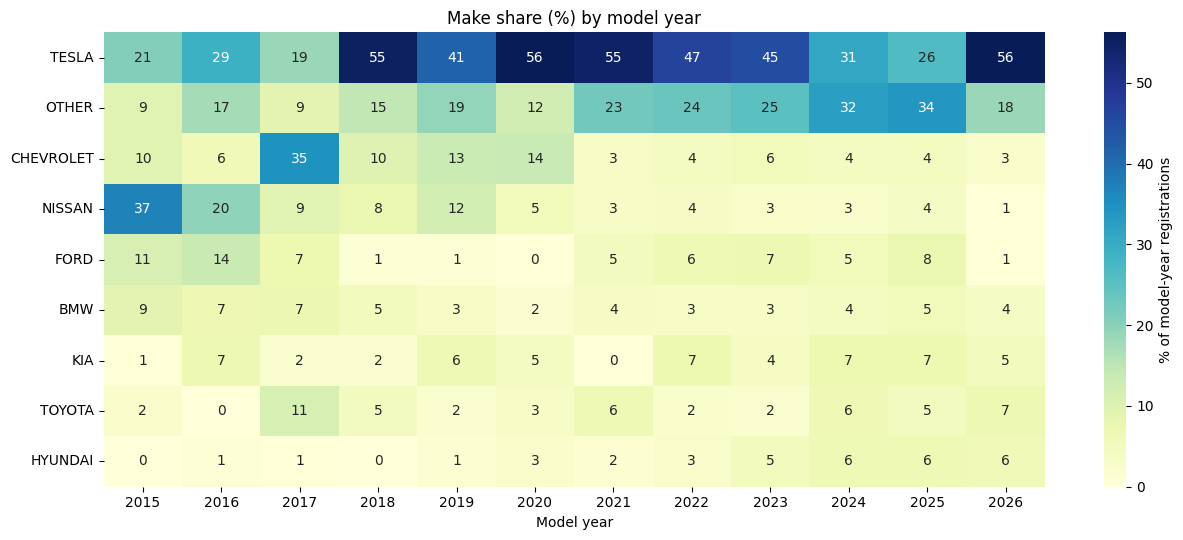

In [59]:
top8 = df["Make"].value_counts().head(8).index
make_grouped = df["Make"].where(df["Make"].isin(top8), "OTHER")

make_year = (pd.crosstab(make_grouped, df["Model Year"], normalize="columns") * 100).loc[:, 2015:2026]
make_year = make_year.loc[make_year.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(13, 5.5))
sns.heatmap(make_year, annot=True, fmt=".0f", cmap="YlGnBu", cbar_kws={"label": "% of model-year registrations"}, ax=ax)
ax.set_title("Make share (%) by model year")
ax.set_xlabel("Model year"); ax.set_ylabel("")
save_fig("12_make_share_by_year")

###  CAFV eligibility by EV type

Clean Alternative Fuel Vehicle (CAFV) Eligibility,Clean Alternative Fuel Vehicle Eligible,Eligibility unknown as battery range has not been researched,Not eligible due to low battery range
Electric Vehicle Type,,,
BEV,18.8,81.2,0.0
PHEV,58.3,0.0,41.7


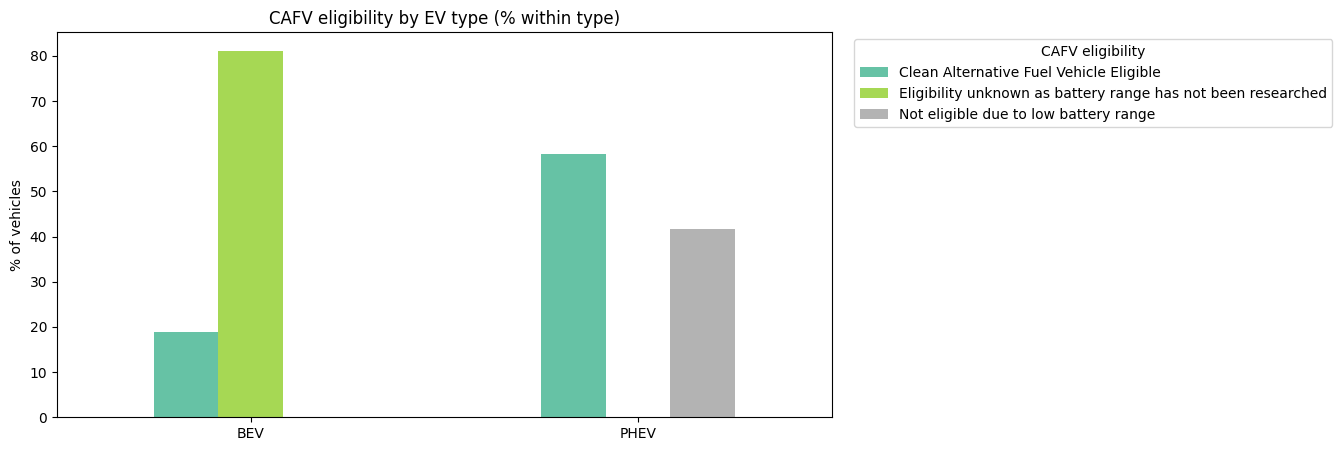

In [61]:
ct = pd.crosstab(df["Electric Vehicle Type"], df["Clean Alternative Fuel Vehicle (CAFV) Eligibility"], normalize="index") * 100
ax = ct.plot.bar(figsize=(10, 5), rot=0, colormap="Set2")
ax.set_title("CAFV eligibility by EV type (% within type)")
ax.set_xlabel(""); ax.set_ylabel("% of vehicles")
ax.legend(title="CAFV eligibility", bbox_to_anchor=(1.02, 1), loc="upper left")
ct.round(1)

**Insight:** CAFV status mirrors the range-data gap. For **BEVs, ~81% are "Unknown"** (the same vehicles with no range researched). For **PHEVs, ~58% are eligible and ~42% fall below the range threshold**, so PHEV eligibility is the only reliable comparison here.

##  Feature engineering

### Vehicle features

In [67]:
# Age of the vehicle relative to the reference year (clipped: model year 2027 would be -1)
REFERENCE_YEAR = 2026
df["vehicle_age"] = (REFERENCE_YEAR - df["Model Year"]).clip(lower=0)

# Adoption era (bins based on the registration curve seen in section 5.4)
df["ev_era"] = pd.cut(
    df["Model Year"],
    bins=[-np.inf, 2015, 2019, 2022, np.inf],
    labels=["Pioneer (≤2015)", "Early adoption (2016-19)", "Mainstream (2020-22)", "Surge (2023+)"],
    ordered=True,
)

# Full vehicle name, and a Tesla flag (by far the dominant make)
df["Make_model"] = df["Make"] + " " + df["Model"]
df["is_tesla"] = (df["Make"] == "TESLA").astype(int)

# Group rare makes into "OTHER" to keep cardinality low (top 10 makes kept)
top_makes = df["Make"].value_counts().head(10).index
df["make_group"] = df["Make"].where(df["Make"].isin(top_makes), "OTHER")

df[["Model Year", "vehicle_age", "ev_era", "Make_model", "make_group", "is_tesla"]].sample(6, random_state=1)

,Model Year,vehicle_age,ev_era,Make_model,make_group,is_tesla
224110,2021,5,Mainstream (2020-22),MITSUBISHI OUTLANDER,OTHER,0
123026,2024,2,Surge (2023+),JEEP WRANGLER,OTHER,0
226097,2017,9,Early adoption (2016-19),FORD FUSION,FORD,0
42777,2014,12,Pioneer (≤2015),CHEVROLET VOLT,CHEVROLET,0
61110,2025,1,Surge (2023+),VOLVO XC60,VOLVO,0
252202,2023,3,Surge (2023+),KIA SPORTAGE,KIA,0


###  Powertrain & range features

In [68]:
df["is_bev"] = (df["Electric Vehicle Type"] == "BEV").astype(int)
df["is_cafv_eligible"] = (df["Clean Alternative Fuel Vehicle (CAFV) Eligibility"] == "Eligible").astype(int)
df["range_known_flag"] = df["Electric Range"].notna().astype(int)

# Range bucket – unknown ranges get their own explicit category instead of being silently dropped
range_bins = pd.cut(
    df["Electric Range"],
    bins=[0, 100, 200, 300, np.inf],
    right=False,
    labels=["Short (<100 mi)", "Medium (100-199 mi)", "Long (200-299 mi)", "Very long (300+ mi)"],
    ordered=True,
)
df["range_category_code"] = range_bins.cat.codes                    # ordinal encoding: 0..3, -1 = unknown
df["range_category"] = range_bins.cat.add_categories("Unknown").fillna("Unknown")

print(df["range_category"].value_counts().to_string())

range_category
Short (<100 mi)        262366
Long (200-299 mi)       29588
Medium (100-199 mi)      5046
Very long (300+ mi)      2679
Unknown                    26


###  Electric utility features

In [71]:
utility_lists = (
    df["Electric Utility"].fillna("")
      .str.split("|", regex=False)
      .apply(lambda parts: [p.strip() for p in parts if p.strip()])
)
df["n_utilities"] = utility_lists.str.len()
df["primary_utility"] = utility_lists.str[0].fillna("Unknown")

print(df["n_utilities"].value_counts().sort_index().to_string())
df[["Electric Utility", "n_utilities", "primary_utility"]].drop_duplicates("Electric Utility").head(5)

n_utilities
0        11
1     75366
2    197189
3     24969
4      2170


,Electric Utility,n_utilities,primary_utility
0,CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),2,CITY OF SEATTLE - (WA)
1,PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),2,PUGET SOUND ENERGY INC
2,PUGET SOUND ENERGY INC,1,PUGET SOUND ENERGY INC
3,PACIFICORP,1,PACIFICORP
146,PUD NO 1 OF CHELAN COUNTY,1,PUD NO 1 OF CHELAN COUNTY


###  Aggregate & frequency-encoded features
These capture **how common** a make/model is and **how EV-dense** a county is.

In [73]:
# Frequency encoding: share of the fleet represented by each make / model
df["make_freq"] = df["Make"].map(df["Make"].value_counts(normalize=True))
df["model_freq"] = df["Model"].map(df["Model"].value_counts(normalize=True))

# County-level aggregates (grouped by state + county so e.g. 'Clark, WA' != 'Clark, NV')
county_grp = df.groupby(["State", "County"])
df["county_ev_count"] = county_grp["DOL Vehicle ID"].transform("size")
df["county_bev_share"] = county_grp["is_bev"].transform("mean")

df[["Make", "make_freq", "Model", "model_freq", "County", "county_ev_count", "county_bev_share"]].sample(5, random_state=3)

,Make,make_freq,Model,model_freq,County,county_ev_count,county_bev_share
59458,TESLA,0.410340,MODEL Y,0.222035,King,144257.0,0.828029
160356,FORD,0.053780,ESCAPE,0.002943,Pierce,25042.0,0.787517
1570,NISSAN,0.053563,LEAF,0.044887,King,144257.0,0.828029
225560,TESLA,0.410340,MODEL S,0.026269,Whatcom,7560.0,0.769709
138222,TESLA,0.410340,MODEL Y,0.222035,Snohomish,37818.0,0.843672
